# Cleaning Pipeline - Exam Exercise Cropping

Ce notebook prépare les copies d'examen scannées pour la classification CNN.

**Objectif** : à partir de 10 dossiers de scans (1 par élève, 15 pages chacun), extraire les 27 exercices individuels de chaque copie.

**Étapes du pipeline** :
1. Suppression des annotations rouges (corrections du professeur)
2. Découpe de chaque exercice selon des coordonnées prédéfinies
3. Export en deux structures : `by_exercise/` et `by_student/`

## 1. Imports et configuration

In [19]:
import cv2
import numpy as np
import json
from pathlib import Path
from IPython.display import display, Image as IPImage
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

In [20]:
DATA_DIR = Path("../data/raw")        # dataset folder SET 1, SET 2, ..., SET 10
OUTPUT_DIR = Path("../data/cleaned")    # output folder

## 2. Configuration des zones de découpe

Chaque page de l'examen contient un nombre fixe d'exercices. Les coordonnées sont **relatives** (entre 0 et 1) par rapport aux dimensions de l'image, ce qui rend le système indépendant de la résolution du scan.

Format : `[y_start, y_end, x_start, x_end]`

- Page 01 = page de garde, pas d'exercice
- Page 03 = 1 seul exercice : la page entière (q03). Les numéros q04 à q06 ne sont pas utilisés, pour garder la même numérotation que les autres exercices
- Toutes les autres pages = 2 exercices chacune

**Pas d'alignement des scans** : le décalage entre scans a été mesuré par rapport au SET 1 (transformation affine estimée sur features ORB, pages 02 à 15). Il est en général de 1 à 1,5 % de la hauteur de page (max ~2 %), avec une rotation < 1,2° et une variation d'échelle de ±2 %. Ce décalage varie d'une page à l'autre, sans biais constant par élève. Un crop à coordonnées fixes suffit donc. Les deux zones d'une même page se chevauchent de 2 % autour de la séparation pour absorber ce décalage, sans risquer de couper une réponse.

Les SET 1-2 (1652x2338 px) et SET 3-5 (2480x3509 px) n'ont pas la même résolution. Les coordonnées relatives gèrent cette différence.

In [21]:
CROP_CONFIG = {
    "02": {
        "q01": [0.03, 0.48, 0.04, 0.96],
        "q02": [0.46, 0.93, 0.04, 0.96]
    },
    "03": {"q03": [0.03, 0.93, 0.04, 0.96]},  # page entière = 1 exercice
    "04": {"q07": [0.03, 0.49, 0.04, 0.96], "q08": [0.47, 0.93, 0.04, 0.96]},
    "05": {"q09": [0.03, 0.49, 0.04, 0.96], "q10": [0.47, 0.93, 0.04, 0.96]},
    "06": {"q11": [0.03, 0.49, 0.04, 0.96], "q12": [0.47, 0.93, 0.04, 0.96]},
    "07": {"q13": [0.03, 0.49, 0.04, 0.96], "q14": [0.47, 0.93, 0.04, 0.96]},
    "08": {"q15": [0.03, 0.49, 0.04, 0.96], "q16": [0.47, 0.93, 0.04, 0.96]},
    "09": {"q17": [0.03, 0.49, 0.04, 0.96], "q18": [0.47, 0.93, 0.04, 0.96]},
    "10": {"q19": [0.03, 0.49, 0.04, 0.96], "q20": [0.47, 0.93, 0.04, 0.96]},
    "11": {"q21": [0.03, 0.49, 0.04, 0.96], "q22": [0.47, 0.93, 0.04, 0.96]},
    "12": {"q23": [0.03, 0.49, 0.04, 0.96], "q24": [0.47, 0.93, 0.04, 0.96]},
    "13": {"q25": [0.03, 0.49, 0.04, 0.96], "q26": [0.47, 0.93, 0.04, 0.96]},
    "14": {"q27": [0.03, 0.49, 0.04, 0.96], "q28": [0.47, 0.93, 0.04, 0.96]},
    "15": {"q29": [0.03, 0.49, 0.04, 0.96], "q30": [0.47, 0.93, 0.04, 0.96]}
}

print(f"Pages configurées : {len(CROP_CONFIG)}")
print(f"Total exercices : {sum(len(q) for q in CROP_CONFIG.values())}")

Pages configurées : 14
Total exercices : 27


## 3. Fonctions du pipeline

### 3.1 Suppression des annotations rouges

Le professeur corrige au **stylo rouge**. Les élèves écrivent au **crayon gris**. L'énoncé est imprimé en **noir**.

On utilise l'espace colorimétrique HSV pour isoler les pixels rouges. Le rouge "wrappe" autour de la valeur de teinte (hue), donc il faut deux plages :
- Hue 0-12 (rouge orangé)
- Hue 165-180 (rouge violacé)

Les pixels rouges détectés sont remplacés par du blanc.

In [ ]:
def remove_red_annotations(img):
    
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    
    # Le rouge wrappe en HSV, donc deux plages
    mask1 = cv2.inRange(hsv, (0, 40, 40), (12, 255, 255))    # rouge-orangé
    mask2 = cv2.inRange(hsv, (165, 40, 40), (180, 255, 255))  # rouge-violacé
    red_mask = mask1 | mask2
    
    # Dilatation légère pour attraper les bords des traits rouges
    kernel = np.ones((3, 3), np.uint8)
    red_mask = cv2.dilate(red_mask, kernel, iterations=1)
    
    # Remplacement par du blanc
    result = img.copy()
    result[red_mask > 0] = [255, 255, 255]
    
    return result

### 3.2 Découpe des exercices

Chaque exercice est découpé avec des coordonnées relatives `[y1, y2, x1, x2]` (entre 0 et 1). On multiplie par les dimensions réelles de l'image pour obtenir les pixels.

In [ ]:
def crop_question(img, coords):
    
    h, w = img.shape[:2]
    y1, y2, x1, x2 = coords
    py1, py2 = int(y1 * h), int(y2 * h)
    px1, px2 = int(x1 * w), int(x2 * w)
    
    # Clamping aux limites de l'image
    py1 = max(0, min(py1, h))
    py2 = max(0, min(py2, h))
    px1 = max(0, min(px1, w))
    px2 = max(0, min(px2, w))
    
    return img[py1:py2, px1:px2]

### 3.3 Utilitaires pour trouver les fichiers

In [ ]:
def find_sets(data_dir):
  
    data_path = Path(data_dir)
    sets = sorted([d for d in data_path.iterdir() 
                   if d.is_dir() and d.name.upper().startswith("SET")])
    if not sets:
        sets = sorted([d for d in data_path.iterdir() if d.is_dir()])
    return sets


def find_page_image(set_dir, page_num):

    page_str = f"{page_num:02d}"
    extensions = [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]
    
    for ext in extensions:
        for pattern in [f"{page_str}{ext}", f"page_{page_str}{ext}", f"{page_num}{ext}"]:
            p = set_dir / pattern
            if p.exists():
                return p
    return None

## 4. Découverte des données

Avant de lancer le pipeline, on vérifie que les dossiers et images sont bien là.

In [26]:
sets = find_sets(DATA_DIR)
print(f"SETs trouvés : {len(sets)}")
for s in sets:
    images = list(s.glob("*.*"))
    print(f"  {s.name} : {len(images)} fichiers")

SETs trouvés : 5
  SET 1 : 16 fichiers
  SET 2 : 16 fichiers
  SET 3 : 15 fichiers
  SET 4 : 15 fichiers
  SET 5 : 15 fichiers


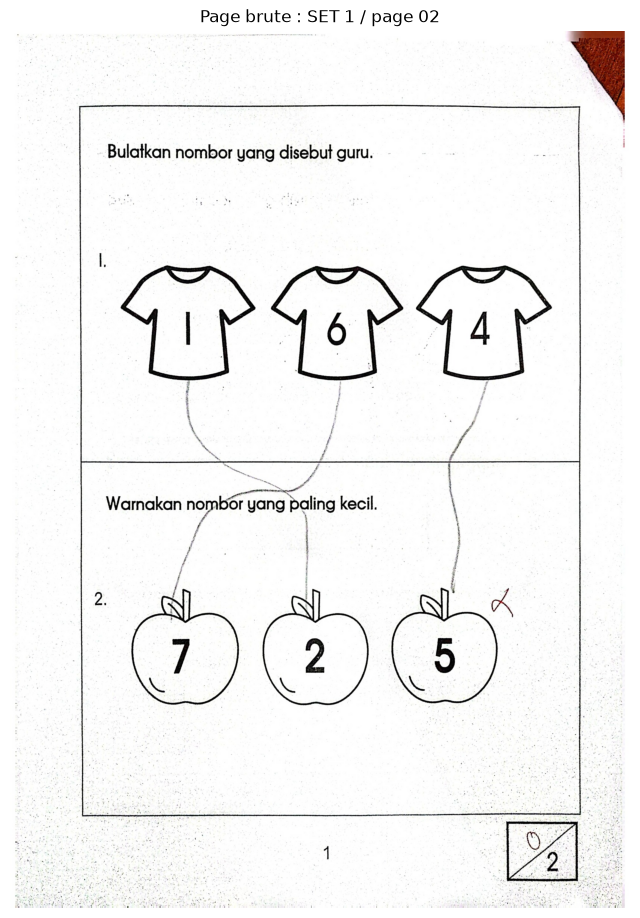

Dimensions : 1652x2338 px


In [27]:
# Aperçu d'une page brute (avant tout traitement)
sample_set = sets[0]
sample_path = find_page_image(sample_set, 2)  # page 2 = première page avec exercices
if sample_path:
    sample_img = cv2.imread(str(sample_path))
    plt.figure(figsize=(8, 12))
    plt.imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Page brute : {sample_set.name} / page 02")
    plt.axis('off')
    plt.show()
    print(f"Dimensions : {sample_img.shape[1]}x{sample_img.shape[0]} px")
else:
    print("Page 02 non trouvée, vérifie le nommage des fichiers")

## 5. Démonstration du pipeline sur une page

On visualise chaque étape du traitement sur une page pour vérifier que tout fonctionne avant de lancer sur l'ensemble.

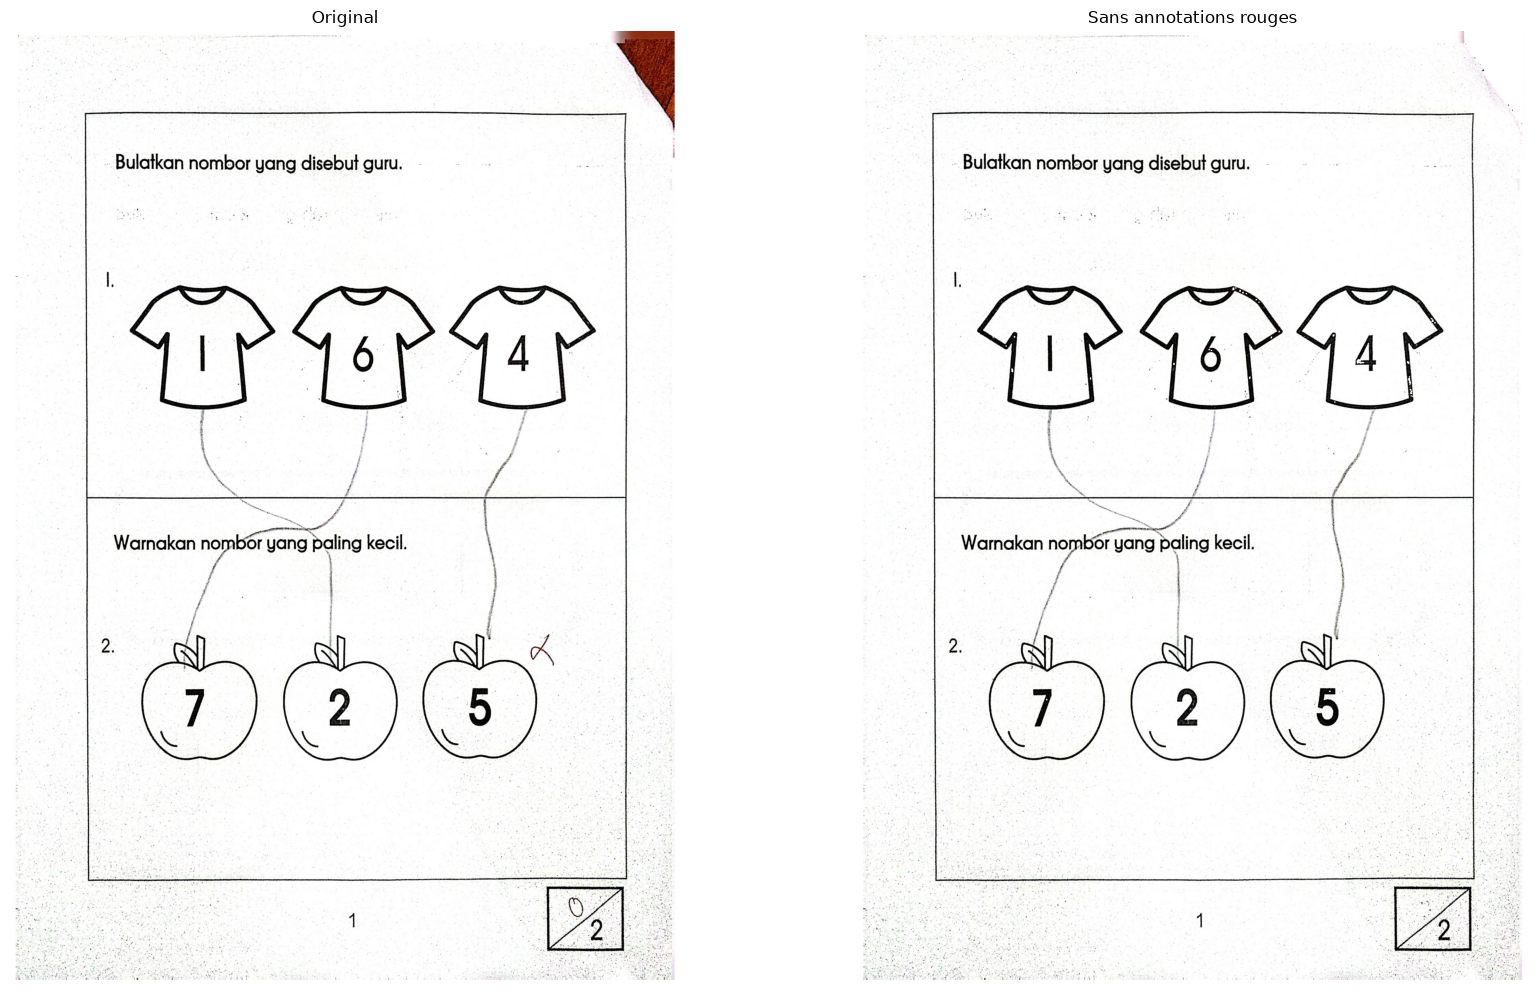

In [28]:
if sample_path:
    img = cv2.imread(str(sample_path))
    
    img_clean = remove_red_annotations(img)
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 10))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(img_clean, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Sans annotations rouges")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

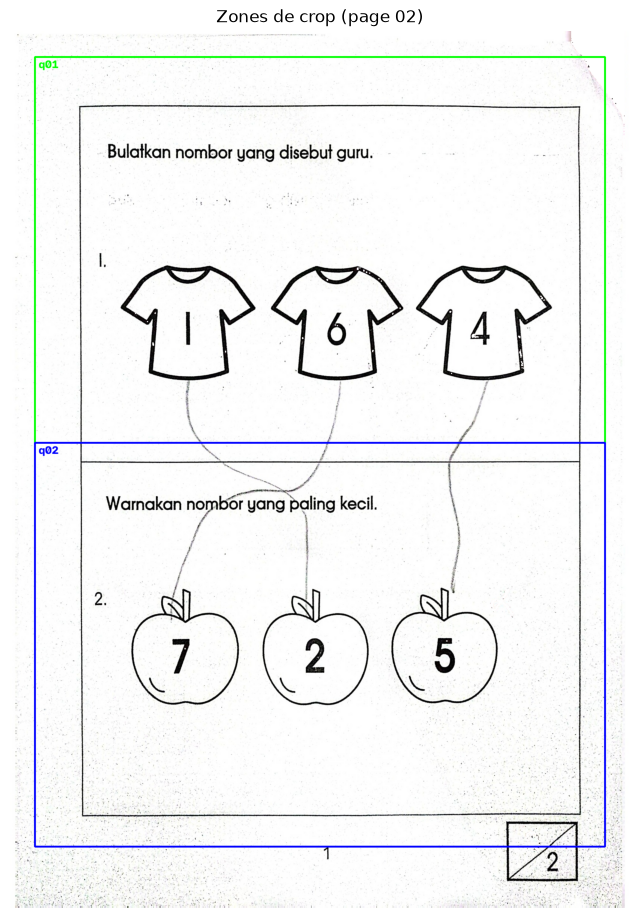

In [29]:
# Visualisation des zones de crop sur la page nettoyée
if sample_path:
    img_debug = img_clean.copy()
    h, w = img_debug.shape[:2]
    colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
    
    page_config = CROP_CONFIG.get("02", {})
    for i, (q_name, coords) in enumerate(page_config.items()):
        y1, y2, x1, x2 = coords
        pt1 = (int(x1 * w), int(y1 * h))
        pt2 = (int(x2 * w), int(y2 * h))
        color = colors[i % len(colors)]
        cv2.rectangle(img_debug, pt1, pt2, color, 3)
        cv2.putText(img_debug, q_name, (pt1[0] + 10, pt1[1] + 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
    
    plt.figure(figsize=(8, 12))
    plt.imshow(cv2.cvtColor(img_debug, cv2.COLOR_BGR2RGB))
    plt.title("Zones de crop (page 02)")
    plt.axis('off')
    plt.show()

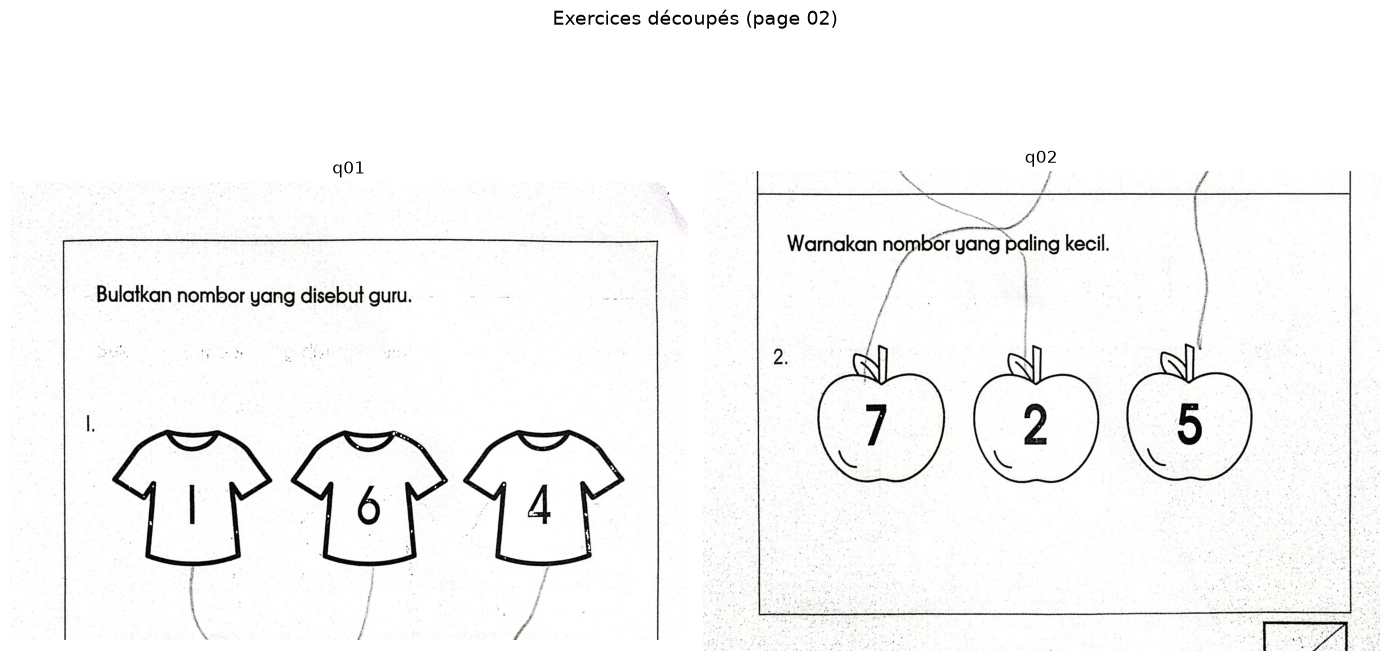

In [30]:
# Aperçu des crops individuels
if sample_path:
    page_config = CROP_CONFIG.get("02", {})
    fig, axes = plt.subplots(1, len(page_config), figsize=(14, 8))
    if len(page_config) == 1:
        axes = [axes]
    
    for ax, (q_name, coords) in zip(axes, page_config.items()):
        crop = crop_question(img_clean, coords)
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(q_name)
        ax.axis('off')
    
    plt.suptitle("Exercices découpés (page 02)", fontsize=14)
    plt.tight_layout()
    plt.show()

## 6. Exécution du pipeline complet

On traite maintenant tous les SETs. Pour chaque page de chaque SET :
1. Suppression du rouge
2. Découpe des exercices

**Sortie** :
- `by_exercise/q01/` ... `by_exercise/q30/` : tous les élèves pour un exercice donné (utile pour comparer)
- `by_student/set_1/` ... `by_student/set_10/` : tous les exercices d'un élève donné

In [31]:
# Création des dossiers de sortie
by_exercise_dir = OUTPUT_DIR / "by_exercise"
by_student_dir = OUTPUT_DIR / "by_student"
verify_dir = OUTPUT_DIR / "verify"

by_exercise_dir.mkdir(parents=True, exist_ok=True)
by_student_dir.mkdir(parents=True, exist_ok=True)
verify_dir.mkdir(parents=True, exist_ok=True)

print("Dossiers de sortie créés")

Dossiers de sortie créés


In [ ]:
# Pipeline principal
stats = {"processed": 0, "skipped": 0, "empty_crops": 0}

for set_dir in sets:
    set_name = set_dir.name.lower().replace(" ", "_")
    print(f"\n{'='*50}")
    print(f"Traitement de {set_dir.name}...")
    
    # Dossier élève
    student_dir = by_student_dir / set_name
    student_dir.mkdir(parents=True, exist_ok=True)
    
    # Dossier vérification
    verify_set_dir = verify_dir / set_name
    verify_set_dir.mkdir(parents=True, exist_ok=True)
    
    for page_str, questions in CROP_CONFIG.items():
        page_num = int(page_str)
        img_path = find_page_image(set_dir, page_num)
        
        if img_path is None:
            print(f"  Page {page_str} : NON TROUVÉE")
            stats["skipped"] += 1
            continue
        
        img = cv2.imread(str(img_path))
        if img is None:
            print(f"  Page {page_str} : ILLISIBLE")
            stats["skipped"] += 1
            continue
        
        print(f"  Page {page_str} ({len(questions)} exercices)...")
        
        img_clean = remove_red_annotations(img)
        
        # Découpe
        for q_name, coords in questions.items():
            crop = crop_question(img_clean, coords)
            
            if crop.size == 0:
                print(f"    {q_name} : crop vide !")
                stats["empty_crops"] += 1
                continue
            
            filename = f"{set_name}_{q_name}.jpg"
            
            # by_exercise
            exercise_dir = by_exercise_dir / q_name
            exercise_dir.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(exercise_dir / filename), crop)
            
            # by_student
            cv2.imwrite(str(student_dir / f"{q_name}.jpg"), crop)
            
            stats["processed"] += 1
        
        # Sauvegarde vérification : zones de crop dessinées
        img_debug = img_clean.copy()
        h, w = img_debug.shape[:2]
        colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
        for i, (q_name, coords) in enumerate(questions.items()):
            y1, y2, x1, x2 = coords
            pt1 = (int(x1 * w), int(y1 * h))
            pt2 = (int(x2 * w), int(y2 * h))
            color = colors[i % len(colors)]
            cv2.rectangle(img_debug, pt1, pt2, color, 3)
            cv2.putText(img_debug, q_name, (pt1[0] + 10, pt1[1] + 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
        cv2.imwrite(str(verify_set_dir / f"page_{page_str}_zones.jpg"), img_debug)

print(f"\n{'='*50}")
print(f"TERMINÉ !")
print(f"Crops générés : {stats['processed']}")
print(f"Pages ignorées : {stats['skipped']}")
print(f"Crops vides : {stats['empty_crops']}")

## 7. Vérification des résultats

On affiche quelques crops pour vérifier visuellement que les zones sont correctes et que le rouge a bien été supprimé.

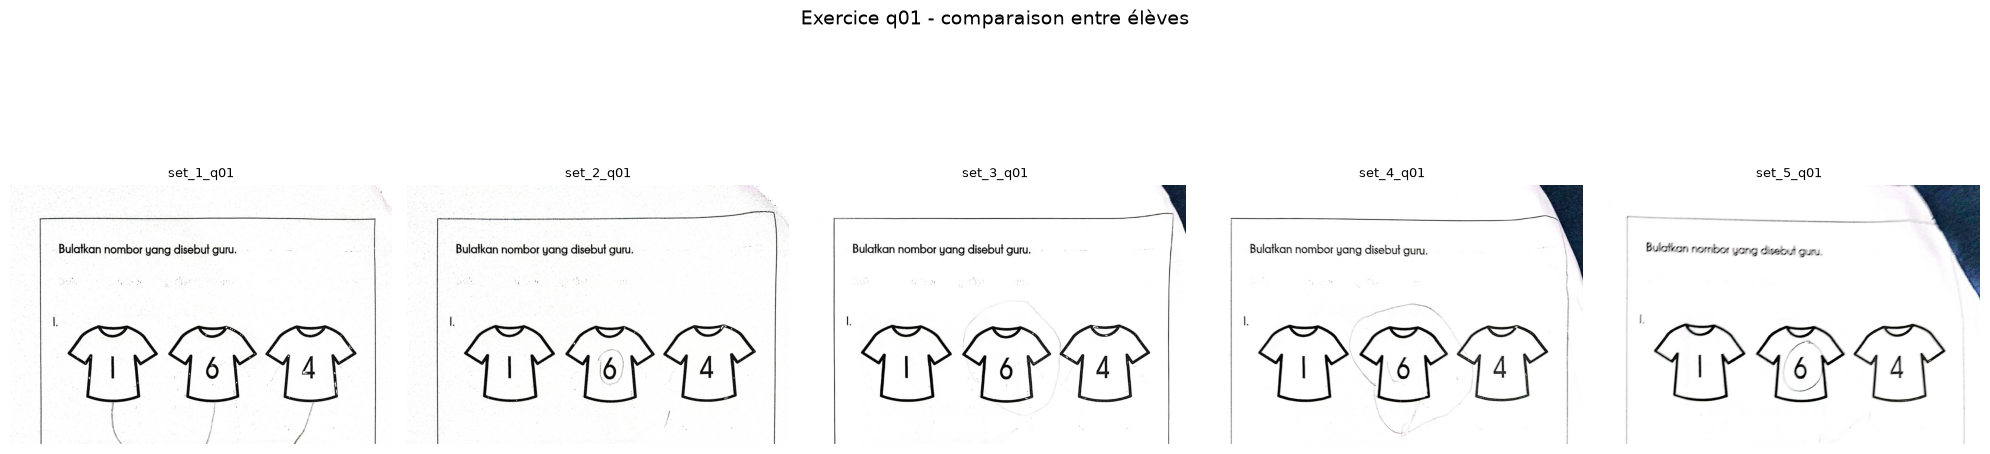

In [34]:
# Vérification : comparer le même exercice entre plusieurs élèves
exercise_to_check = "q01"  # modifier pour vérifier d'autres exercices

exercise_path = by_exercise_dir / exercise_to_check
if exercise_path.exists():
    crops = sorted(exercise_path.glob("*.jpg"))[:5]  # 5 premiers
    
    fig, axes = plt.subplots(1, len(crops), figsize=(20, 6))
    if len(crops) == 1:
        axes = [axes]
    
    for ax, crop_path in zip(axes, crops):
        crop_img = cv2.imread(str(crop_path))
        ax.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
        ax.set_title(crop_path.stem, fontsize=9)
        ax.axis('off')
    
    plt.suptitle(f"Exercice {exercise_to_check} - comparaison entre élèves", fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print(f"Dossier {exercise_to_check} non trouvé")

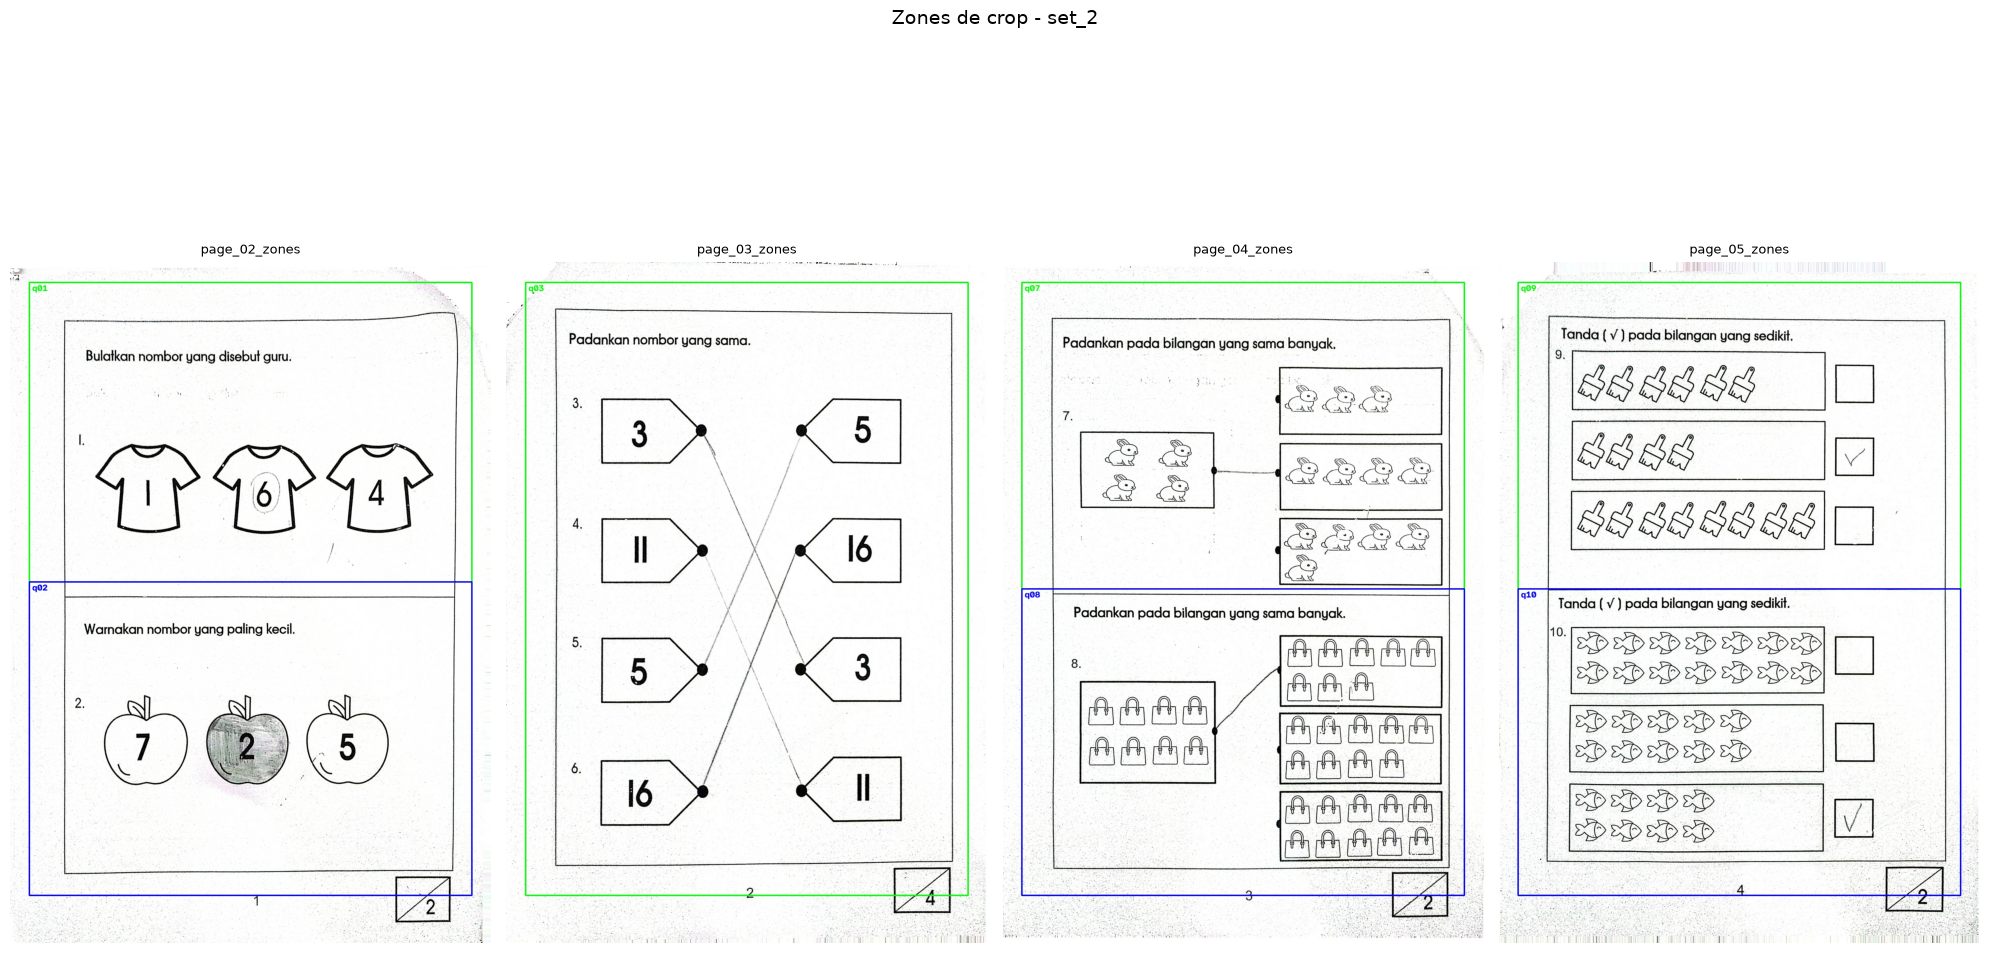

In [35]:
# Vérification : afficher les zones de crop pour un SET donné
set_to_check = sets[1].name.lower().replace(" ", "_") if len(sets) > 1 else sets[0].name.lower().replace(" ", "_")

verify_set_path = verify_dir / set_to_check
if verify_set_path.exists():
    zone_files = sorted(verify_set_path.glob("*_zones.jpg"))[:4]
    
    fig, axes = plt.subplots(1, len(zone_files), figsize=(20, 12))
    if len(zone_files) == 1:
        axes = [axes]
    
    for ax, zf in zip(axes, zone_files):
        zone_img = cv2.imread(str(zf))
        ax.imshow(cv2.cvtColor(zone_img, cv2.COLOR_BGR2RGB))
        ax.set_title(zf.stem, fontsize=9)
        ax.axis('off')
    
    plt.suptitle(f"Zones de crop - {set_to_check}", fontsize=14)
    plt.tight_layout()
    plt.show()

## 8. Statistiques du dataset

Récapitulatif de ce qui a été généré.

In [36]:
print("Structure de sortie :")
print(f"  {OUTPUT_DIR}/")
print(f"  +-- by_exercise/")

for q_dir in sorted(by_exercise_dir.iterdir()):
    if q_dir.is_dir():
        count = len(list(q_dir.glob("*.jpg")))
        print(f"  |   +-- {q_dir.name}/  ({count} images)")

print(f"  +-- by_student/")
for s_dir in sorted(by_student_dir.iterdir()):
    if s_dir.is_dir():
        count = len(list(s_dir.glob("*.jpg")))
        print(f"      +-- {s_dir.name}/  ({count} exercices)")

total = sum(1 for _ in by_exercise_dir.rglob("*.jpg"))
print(f"\nTotal crops : {total}")
n_exercises = sum(len(q) for q in CROP_CONFIG.values())
print(f"Attendu : {len(sets)} élèves x {n_exercises} exercices = {len(sets) * n_exercises}")

Structure de sortie :
  ..\data\cleaned/
  +-- by_exercise/
  |   +-- q01/  (5 images)
  |   +-- q02/  (5 images)
  |   +-- q03/  (5 images)
  |   +-- q07/  (5 images)
  |   +-- q08/  (5 images)
  |   +-- q09/  (5 images)
  |   +-- q10/  (5 images)
  |   +-- q11/  (5 images)
  |   +-- q12/  (5 images)
  |   +-- q13/  (5 images)
  |   +-- q14/  (5 images)
  |   +-- q15/  (5 images)
  |   +-- q16/  (5 images)
  |   +-- q17/  (5 images)
  |   +-- q18/  (5 images)
  |   +-- q19/  (5 images)
  |   +-- q20/  (5 images)
  |   +-- q21/  (5 images)
  |   +-- q22/  (5 images)
  |   +-- q23/  (5 images)
  |   +-- q24/  (5 images)
  |   +-- q25/  (5 images)
  |   +-- q26/  (5 images)
  |   +-- q27/  (5 images)
  |   +-- q28/  (5 images)
  |   +-- q29/  (5 images)
  |   +-- q30/  (5 images)
  +-- by_student/
      +-- set_1/  (27 exercices)
      +-- set_2/  (27 exercices)
      +-- set_3/  (27 exercices)
      +-- set_4/  (27 exercices)
      +-- set_5/  (27 exercices)

Total crops : 135
Attendu :